In [48]:
from ase import io
from ase.mep import NEB
from ase.optimize import MDMin


from ase.build import fcc111, add_adsorbate
from ase import Atoms
from ase.constraints import FixAtoms
from mace.calculators import mace_mp

In [49]:
mace_calc = mace_mp(model="medium", dispersion=True, default_dtype="float64",device='cuda:1', )

# Create a 4x4 Rh(111) slab with 4 layers and 10 Å of vacuum
slab = fcc111('Rh', size=(4, 4, 4), vacuum=10.0)

# Define the HCO molecule
HCO = Atoms('HCO', positions=[(0, 0, 0), (1.1, 0, 0), (1.1, 1.2, 0)])

# Define the adsorption height for HCO above the hollow site (adjust as necessary)
adsorption_height = 1.5  # distance in Angstroms from the slab

# Add HCO to the hollow site of the slab (hollow = position between 3 neighboring atoms)
# You can specify 'hollow' directly to target the hollow site
add_adsorbate(slab, HCO, adsorption_height, position=(5,3))

# Freeze the lowest layer of the slab (z_threshold sets the cutoff for the lowest layer)
z_threshold = min(slab.positions[:, 2]) + 0.1
constraint = FixAtoms(indices=[atom.index for atom in slab if atom.position[2] < z_threshold])
slab.set_constraint(constraint)





Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

In [50]:
from ase.optimize import BFGS
slab.calc = mace_calc
BFGS(slab,trajectory="initial.traj").run(fmax=0.05,steps=150)
initial = slab.copy()

      Step     Time          Energy          fmax
BFGS:    0 09:55:44     -498.098771       11.572411
BFGS:    1 09:55:44     -499.924290        4.296589
BFGS:    2 09:55:44     -500.464918        3.427215
BFGS:    3 09:55:45     -501.053731        5.426593
BFGS:    4 09:55:45     -501.385206        1.871499
BFGS:    5 09:55:45     -501.532703        1.867871
BFGS:    6 09:55:46     -501.810254        2.647768
BFGS:    7 09:55:46     -501.901325        1.813422
BFGS:    8 09:55:46     -502.017940        0.718602
BFGS:    9 09:55:46     -502.076397        0.825608
BFGS:   10 09:55:47     -502.157313        0.767642
BFGS:   11 09:55:47     -502.190109        1.048137
BFGS:   12 09:55:47     -502.197318        1.359543
BFGS:   13 09:55:47     -502.241568        0.606513
BFGS:   14 09:55:48     -502.270433        0.477581
BFGS:   15 09:55:48     -502.303676        0.392411
BFGS:   16 09:55:48     -502.315207        0.342715
BFGS:   17 09:55:49     -502.329155        0.467024
BFGS:   18 09:

In [51]:
# Create a 4x4 Rh(111) slab with 4 layers and 10 Å of vacuum
slab = fcc111('Rh', size=(4, 4, 4), vacuum=10.0)

# Define the HCO molecule
HCO = Atoms('CO', positions=[(0, 0, 0), (1.2, 0, 0)])
H_atom = Atoms('H', positions=[(0, 0, 0)])
# Define the adsorption height for HCO above the hollow site (adjust as necessary)
adsorption_height = 1.5  # distance in Angstroms from the slab

# Add HCO to the hollow site of the slab (hollow = position between 3 neighboring atoms)
# You can specify 'hollow' directly to target the hollow site
add_adsorbate(slab, H_atom, adsorption_height, position=(6,1))
add_adsorbate(slab, HCO, adsorption_height, position=(5,3))


# Freeze the lowest layer of the slab (z_threshold sets the cutoff for the lowest layer)
z_threshold = min(slab.positions[:, 2]) + 0.1
constraint = FixAtoms(indices=[atom.index for atom in slab if atom.position[2] < z_threshold])
slab.set_constraint(constraint)

slab.calc = mace_calc
BFGS(slab,trajectory="finial.traj").run(fmax=0.05,steps=150)
final = slab.copy()

      Step     Time          Energy          fmax
BFGS:    0 09:55:56     -498.626690        9.021167
BFGS:    1 09:55:56     -499.959007        3.834160
BFGS:    2 09:55:57     -500.531346        2.393833
BFGS:    3 09:55:57     -501.281528        2.098267
BFGS:    4 09:55:57     -501.671796        3.485449
BFGS:    5 09:55:58     -501.977585        2.192490
BFGS:    6 09:55:58     -502.490890        0.969457
BFGS:    7 09:55:58     -502.701156        2.463203
BFGS:    8 09:55:58     -502.356009        9.422724
BFGS:    9 09:55:59     -502.826754        1.503111
BFGS:   10 09:55:59     -502.877853        0.681251
BFGS:   11 09:55:59     -502.941696        0.466836
BFGS:   12 09:55:59     -503.029478        0.635515
BFGS:   13 09:56:00     -503.048646        0.691194
BFGS:   14 09:56:00     -503.095954        0.436908
BFGS:   15 09:56:00     -503.120300        0.425275
BFGS:   16 09:56:00     -503.137066        0.277087
BFGS:   17 09:56:01     -503.145650        0.587729
BFGS:   18 09:

In [ ]:
from ase.io import write

In [ ]:
# Make a band consisting of 5 images:
images = [initial]
images += [initial.copy() for i in range(8)]
images += [final]
neb = NEB(images)
# Interpolate linearly the potisions of the middle images:
neb.interpolate()
# Set calculators:
for i, image in enumerate(images):
    write(f"NEB_interpolate_HCO_on_Rh_{i}.traj",image)

In [ ]:
write("NEB_interpolate_HCO_on_Rh.traj",images)

In [ ]:
for image in images[1:9]:
    image.calc = mace_mp(model="medium", dispersion=True, default_dtype="float64",device='cuda:1', )
optimizer = BFGS(neb, trajectory='NEB_CHO_Rh.traj')
optimizer.run(fmax=0.05)

Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
      Step     Time          Energy          fmax
BFGS:    0 09:35:43     -502.191642        4.812921
BFGS:    1 09:35:46     -502.162617        4.458755
BFGS:    2 09:35:48     -502.305894        1.735625
BFGS:    3 09:35:51     -502.342173        1.778041
BFGS:    4 09:35:53     -502.375679        1.215925
BFGS:    5 09:35:56     -502.424496        1.348685
BFGS:    6 09:35:58     -502.423348        1.110500
BFGS:    7 09:36:01     -502.425804        0.787307
BFGS:    8 09:36:04     -502.430417        0.982417
BFGS:    9 09:36:06     -502.431203        0.791729
BFGS:   10 09:36:09     -502.431443        0.391226
BFGS:   11 09:36:11     -502.432814        0.342315
BFGS:   12 09:36:13     -502.436152        0.834960
BFGS:   13 09:36:16     -502.435863        0.465716
BFGS:   14 09:36:18     -502.436275        0.279122
BFGS:   15 09:36:21     -502.437974        0.313349
BFGS:   16

True

In [ ]:
from ase.io import Trajectory
import matplotlib.pyplot as plt

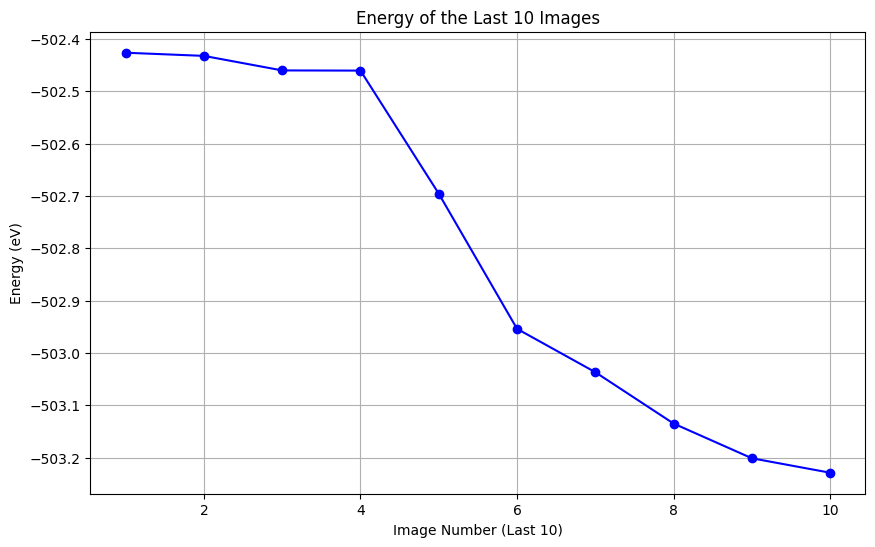

In [ ]:
traj = Trajectory("NEB_CHO_Rh.traj")
# Extract the last 10 images
last_10_images = traj[-10:]

# Extract energies from the last 10 images
energies = []
for image in last_10_images:
    image.calc=mace_calc
    energies.append(image.get_potential_energy() )

# Plot the energies
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), energies, marker='o', linestyle='-', color='b')
plt.xlabel('Image Number (Last 10)')
plt.ylabel('Energy (eV)')
plt.title('Energy of the Last 10 Images')
plt.grid(True)
plt.show()

In [ ]:
# Make a band consisting of 5 images:
images = [initial]
images += [initial.copy() for i in range(8)]
images += [final]
neb = NEB(images,climb=True)
# Interpolate linearly the potisions of the middle images:
neb.interpolate()
# Set calculators:
for i, image in enumerate(images):
    write(f"NEB_interpolate_HCO_on_Rh_{i}_ci.traj",image)
write("NEB_interpolate_HCO_on_Rh_ci.traj",images)

for image in images[1:9]:
    image.calc = mace_mp(model="medium", dispersion=True, default_dtype="float64",device='cuda:1', )
optimizer = BFGS(neb, trajectory='NEB_CHO_Rh_ci.traj')
optimizer.run(fmax=0.05)

Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
      Step     Time          Energy          fmax
BFGS:    0 09:53:14     -502.191642        4.812921
BFGS:    1 09:53:17     -502.162417        4.458755
BFGS:    2 09:53:20     -502.305397        1.737375
BFGS:    3 09:53:23     -502.341569        1.779096
BFGS:    4 09:53:26     -502.375259        1.216048
BFGS:    5 09:53:30     -502.424568        1.333500
BFGS:    6 09:53:32     -502.423368        1.106909
BFGS:    7 09:53:35     -502.425806        0.772196
BFGS:    8 09:53:37     -502.430350        0.970769
BFGS:    9 09:53:39     -502.431134        0.774273
BFGS:   10 09:53:42     -502.431278        0.397023
BFGS:   11 09:53:44     -502.432473        0.338336


KeyboardInterrupt: 

In [ ]:
traj_ci = Trajectory("NEB_CHO_Rh_ci.traj")
# Extract the last 10 images
last_10_images_ci = traj_ci[-10:]

# Extract energies from the last 10 images
energies_ci = []
for image in last_10_images_ci:
    image.calc=mace_calc
    energies_ci.append(image.get_potential_energy() )

# Plot the energies
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), energies, marker='o', linestyle='-', color='b',label="NEB")
plt.plot(range(1, 11), energies_ci, marker='o', linestyle='-', color='b',label="CI NEB")
plt.legend()
plt.xlabel('Image Number (Last 10)')
plt.ylabel('Energy (eV)')
plt.title('Energy of the Last 10 Images')
plt.grid(True)
plt.show()